# 25 · Deployment questions: categorical vendor outputs, a fixed background partner, and more than two systems (post hoc)

**Status: post hoc, exploratory.** Reads only frozen prediction files; writes aggregates only.

**A. Vendors that report only categories.** Each system's score is cut into 2, 3 or 5 ordered categories, as a commercial device might report. Cut-points are set at score quantiles that leave fixed shares of the population above each cut, relative to the referral share f: two categories flag the top f; three categories split the flagged top f into its upper and lower halves; five categories cut at the top f/4, f/2, f and 2f. (Setting cut-points on the local population gives each device a locally sensible operating point, which slightly favours the devices.) Four rules at the same referral share f:
- each system alone on its categories (ties at the cut broken at random, scored as the expected value);
- **maximum rank on categories**: the pair score is the higher category, then the other system's category, with ties at the margin broken at random (expected value);
- **joint table**: for each combination of the two categories, a likelihood ratio for disease is estimated on a patient-disjoint enriched pilot (100 cases and 100 others; 0.5 added to every count), and combinations are referred in descending order until f is used, scored on the remaining images; 30 pilot draws, one training run per design (run 0) to keep runtime down;
- maximum rank on the continuous scores (the main analysis), as the reference.

The headline number is the share of the continuous-score benefit over the average member that each categorical rule keeps. The joint table is also compared with the average member on categories, scored on the same images: removing the pilot patients shifts the evaluation set, so categories cut on the whole population no longer fall exactly at the referral share, which costs a single system some accuracy. This matters only in the small skin sets.

**B. A fixed background partner.** The partner is chosen without test data: the EyePACS-trained system with the highest validation AUC for referable DR. It is paired with every other system acting as the clinic's existing "vendor" in EyePACS, DDR and BRSET (in BRSET also with the DDR-trained systems). Reported: misses avoided versus the vendor alone, regret versus the better of the two, and how often the pair beats the vendor alone.

**C. More than two systems.** For k = 1 to 11 designs (one training run each, run index matched), up to 200 random subsets per k, at the same referral share: maximum rank across the k systems and mean rank across them. Reported against the average member and the best member of each subset. Skin uses k = 1 to 12 variants.

**Runtime:** CPU, about 30 to 60 minutes.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import os, re, json, hashlib, itertools, datetime, time, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
DATA = "/content/drive/MyDrive/stochastic_orthogonality/data"
BASE = f"{DATA}/dr_ensemble_v2"; PREDS, SPLITS = f"{BASE}/03_predictions", f"{BASE}/01_splits"
BRSET_LABELS = f"{DATA}/brset/label_brset.csv"; DERM = f"{DATA}/derm"
OUTD = f"{BASE}/04_results/revisions_c1"; os.makedirs(OUTD, exist_ok=True)
OUT_JSON = f"{OUTD}/deployment_c1.json"
assert not os.path.exists(OUT_JSON), "already written; rename the old output deliberately to rerun"
SEED = 20261030
LEVELS = (2, 3, 5); DRAWS_A, KPILOT_A = 30, (100,)
KSIZES = tuple(range(1, 12)); NSUB = 200
def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
def refer(s, f):
    r = np.zeros(len(s), bool); r[np.argsort(-s, kind="stable")[:int(round(f * len(s)))]] = True; return r
def rk(s): return rankdata(s) / len(s)
def pairscore(ra, rb): return np.maximum(ra, rb) + 1e-9 * np.minimum(ra, rb)
def boot_w(groups, n_boot, seed):
    codes = pd.factorize(groups)[0]; G = codes.max() + 1; rng = np.random.default_rng(seed)
    W = np.empty((n_boot + 1, len(codes)), np.float32); W[0] = 1.0
    for b in range(1, n_boot + 1): W[b] = np.bincount(rng.integers(0, G, G), minlength=G)[codes]
    return W
def ci(x):
    x = np.asarray(x, float); f = x[1:][np.isfinite(x[1:])]
    return [float(x[0]), float(np.percentile(f, 2.5)), float(np.percentile(f, 97.5))]
def ci_basic(x):
    x = np.asarray(x, float); f = x[1:][np.isfinite(x[1:])]
    return [float(x[0]), float(2 * x[0] - np.percentile(f, 97.5)), float(2 * x[0] - np.percentile(f, 2.5))]
def pct(x): x = np.asarray(x, float); return [float(np.mean(x)), float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5))]
def fmt(t, d=2): return f"{t[0]:.{d}f} ({t[1]:.{d}f} to {t[2]:.{d}f})"
def pick(cols, pats, what):
    m = [c for c in cols if any(re.fullmatch(p, c, flags=re.I) for p in pats)]
    assert len(m) == 1, f"cannot identify the {what} column; columns are {list(cols)}"
    return m[0]
def norm(x): return pd.Series(x, dtype=str).str.replace(r"\.(jpe?g|png|tiff?)$", "", regex=True, flags=re.I).to_numpy()
HASHES = {}
print("ready")

Mounted at /content/drive
ready


## 1. Load frozen predictions

In [2]:
ARCHS = ["densenet121_binary", "densenet121_5class", "efficientnet_b3_binary", "efficientnet_b3_5class", "resnet50_binary", "resnet50_5class",
         "vit_base_binary", "vit_base_5class", "retfound_binary", "retfound_5class", "retfound_adversarial"]
CORE4 = ["densenet121_5class", "efficientnet_b3_5class", "resnet50_5class", "retfound_5class"]
RSEEDS = [0, 1, 2]; RMODELS = [(a, k) for a in ARCHS for k in RSEEDS]
def tag(k): return "" if k == 0 else f"_seed{k}"
def load_preds(fmt_):
    P = {}; ref = None
    for a, k in RMODELS:
        fn = f"{PREDS}/{fmt_.format(arch=a, tag=tag(k))}"; HASHES[os.path.basename(fn)] = sha(fn)
        d = pd.read_csv(fn, dtype={"image_id": str})
        if ref is None: ref = d
        else: assert (d.image_id.values == ref.image_id.values).all(), fn
        P[(a, k)] = d["predicted_probability"].to_numpy(np.float64)
    return ref, P
RET = {}
ref, P = load_preds("eyepacs_predictions_fresh_{arch}{tag}_v2.csv")
RET["EyePACS"] = {"grade": ref.true_grade.to_numpy(int), "group": ref.patient_id.astype(str).to_numpy(), "P": P, "f": 0.25}
ref, P = load_preds("ddr_predictions_{arch}{tag}_v2.csv")
sp = pd.read_csv(f"{SPLITS}/ddr_split_intraset_v2.csv", dtype={"image_id": str})
gcol, grpcol = pick(sp.columns, ["grade", "true_grade", "dr_grade", "level"], "DDR grade"), pick(sp.columns, ["group", "filename_group", "group_id"], "DDR group")
sp["_k"] = norm(sp["image_id"]); sp = sp.set_index("_k").loc[norm(ref.image_id)]
g = sp[gcol].to_numpy(int); keep = g <= 4; isA = sp["half"].astype(str).str.upper().eq("A").to_numpy() if "half" in sp.columns else np.ones(len(g), bool)
RET["DDR"] = {"grade": g[keep], "group": sp[grpcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}, "f": round(1.31 * float((g[keep & isA] >= 2).mean()), 4)}
ref, P = load_preds("brset_predictions_eyepacs_{arch}{tag}_v2.csv")
lb = pd.read_csv(BRSET_LABELS, dtype=str)
icol, pcol, idcol = pick(lb.columns, [r".*icdr.*"], "BRSET ICDR grade"), pick(lb.columns, ["patient_id", "patient"], "BRSET patient"), pick(lb.columns, ["image_id", "image"], "BRSET image id")
lb["_k"] = norm(lb[idcol]); lb = lb.set_index("_k").loc[norm(ref.image_id)]
g = pd.to_numeric(lb[icol], errors="coerce").to_numpy(); keep = np.isin(g, [0, 1, 2, 3, 4])
RET["BRSET"] = {"grade": g[keep].astype(int), "group": lb[pcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}}
RET["BRSET"]["f"] = round(1.31 * float((RET["BRSET"]["grade"] >= 2).mean()), 4)
PB = {}
for src in ("eyepacs", "ddr"):
    for a in CORE4:
        for k in RSEEDS:
            fn = f"{PREDS}/brset_predictions_{src}_{a}{tag(k)}_v2.csv"; HASHES[os.path.basename(fn)] = sha(fn)
            d = pd.read_csv(fn, dtype={"image_id": str}); assert (norm(d.image_id) == lb.index.to_numpy()).all(), fn
            PB[(src, a, k)] = d["predicted_probability"].to_numpy(np.float64)[keep]
for n_, d in RET.items(): print(f"{n_:>8}: {len(d['grade']):,} images | {len(set(d['group'])):,} groups | f = {d['f']}")
# skin
CLASSES = ["MEL", "BCC", "SCC", "AK", "NV", "BKL", "DF", "VASC"]; SARCHS = ["resnet50", "densenet121", "efficientnet_b3", "convnext_t", "vit_b", "vit_b_dinov2"]
SOURCES = ["HAM10000", "BCN20000"]; SMODELS = [(s, a, k) for s in SOURCES for a in SARCHS for k in (0, 1)]; VARIANTS = [(s, a) for s in SOURCES for a in SARCHS]
SKIN = {}
for es in ("HIBA", "PAD"):
    D = pd.read_csv(f"{DERM}/manifest_{es}.csv", dtype={"image_id": str, "patient_id": str}).sort_values("image_id")
    D = D[~D.duplicated("raw_sha256", keep="first") & D.dx.isin(CLASSES)].reset_index(drop=True); P = {}
    for m in SMODELS:
        fn = f"{DERM}/predictions/{es}__{m[0]}_{m[1]}_seed{m[2]}.csv"; HASHES[os.path.basename(fn)] = sha(fn)
        p = pd.read_csv(fn, dtype={"image_id": str}).drop_duplicates("image_id").set_index("image_id").reindex(D.image_id); assert p.p_malignant.notna().all(); P[m] = p.p_malignant.to_numpy()
    dx = D.dx.to_numpy(); mal = np.isin(dx, ["MEL", "BCC", "SCC"])
    SKIN[es] = {"dx": dx, "mal": mal, "mel": dx == "MEL", "group": D.patient_id.astype(str).fillna("none").to_numpy(), "P": P, "f": round(1.31 * float(mal.mean()), 4)}
    print(f"{es:>8}: {len(dx):,} images | {len(set(SKIN[es]['group'])):,} patients | f = {SKIN[es]['f']}")

 EyePACS: 15,794 images | 7,897 groups | f = 0.25
     DDR: 12,422 images | 332 groups | f = 0.555
   BRSET: 16,266 images | 8,524 groups | f = 0.0745
    HIBA: 1,616 images | 623 patients | f = 0.6088
     PAD: 2,283 images | 1,373 patients | f = 0.6203


## 2. Rosters

In [3]:
def mname(m): return "_".join(str(x) for x in m)
ROSTERS = []
main_pairs = [((a, i), (b, j), "main roster") for a, b in itertools.combinations(ARCHS, 2) for i in RSEEDS for j in RSEEDS]
for pop in ("EyePACS", "DDR", "BRSET"):
    d = RET[pop]
    ROSTERS.append({"key": f"{pop}_severe", "label": f"{pop}, severe DR", "y": d["grade"] >= 3, "group": d["group"], "P": d["P"], "pairs": main_pairs, "f": d["f"]})
ROSTERS.append({"key": "DDR_pdr", "label": "DDR, PDR", "y": RET["DDR"]["grade"] == 4, "group": RET["DDR"]["group"], "P": RET["DDR"]["P"], "pairs": main_pairs, "f": RET["DDR"]["f"]})
def src_type(a, b):
    if a[0] == b[0]: return f"both {'EyePACS' if a[0] == 'eyepacs' else 'DDR'}-trained"
    return "one of each"
mixed_pairs = [(a, b, src_type(a, b)) for a, b in itertools.combinations(PB, 2) if a[:2] != b[:2]]
ROSTERS.append({"key": "BRSET_mixed_severe", "label": "BRSET, mixed training sources, severe DR", "y": RET["BRSET"]["grade"] >= 3, "group": RET["BRSET"]["group"], "P": PB, "pairs": mixed_pairs, "f": RET["BRSET"]["f"]})
skin_pairs = [((*va, i), (*vb, j), "same collection" if va[0] == vb[0] else "different collection") for va, vb in itertools.combinations(VARIANTS, 2) for i in (0, 1) for j in (0, 1)]
for es in ("HIBA", "PAD"):
    S = SKIN[es]
    for oname, y in (("melanoma", S["mel"]), ("any skin cancer", S["mal"])):
        ROSTERS.append({"key": f"{es}_{'mel' if oname == 'melanoma' else 'mal'}", "label": f"{es}, {oname}", "y": y, "group": S["group"], "P": S["P"], "pairs": skin_pairs, "f": S["f"]})
for R_ in ROSTERS: print(f"{R_['key']:22s} pairs {len(R_['pairs']):4d} | cases {int(R_['y'].sum()):5d} | f {R_['f']}")

EyePACS_severe         pairs  495 | cases   712 | f 0.25
DDR_severe             pairs  495 | cases  1149 | f 0.555
BRSET_severe           pairs  495 | cases   474 | f 0.0745
DDR_pdr                pairs  495 | cases   913 | f 0.555
BRSET_mixed_severe     pairs  252 | cases   474 | f 0.0745
HIBA_mel               pairs  264 | cases   253 | f 0.6088
HIBA_mal               pairs  264 | cases   751 | f 0.6088
PAD_mel                pairs  264 | cases    52 | f 0.6203
PAD_mal                pairs  264 | cases  1081 | f 0.6203


In [4]:
def exp_refer_misses(score, y, f):
    """expected missed cases when referring the top f by score, with ties at the margin broken at random"""
    n = len(score); R = int(round(f * n)); o = np.argsort(-score, kind="stable"); s = score[o]; yy = y[o].astype(float)
    if R == 0: return float(yy.sum())
    if R >= n: return 0.0
    thr = s[R - 1]; above = s > thr; tie = s == thr
    caught = yy[above].sum() + (R - above.sum()) / tie.sum() * yy[tie].sum()
    return float(yy.sum() - caught)
def coarsen(score, f, L):
    shares = {2: [f], 3: [f / 2, f], 5: [f / 4, f / 2, f, 2 * f]}[L]
    cuts = np.quantile(score, [1 - min(s, 0.999) for s in shares])          # high to low share -> ascending cuts reversed
    return np.searchsorted(np.sort(cuts), score, side="right").astype(float)  # 0 = lowest category
def pair_cat(ca, cb): return np.maximum(ca, cb) * 100 + np.minimum(ca, cb)
print("helpers ready")

helpers ready


## A. Categorical vendor outputs

In [5]:
A_RES = {}
A_ROSTERS = ["EyePACS_severe", "DDR_pdr", "BRSET_severe", "HIBA_mel", "HIBA_mal", "PAD_mal"]
for R_ in [r for r in ROSTERS if r["key"] in A_ROSTERS]:
    t0 = time.time(); y, P, f = R_["y"], R_["P"], R_["f"]; pid = pd.factorize(R_["group"])[0]; npat = pid.max() + 1
    used = sorted({m for a, b, _ in R_["pairs"] for m in (a, b)}, key=str); K = {m: rk(P[m]) for m in used}
    cont_single = {m: exp_refer_misses(P[m], y, f) for m in used}
    out = {}
    for L in LEVELS:
        CAT = {m: coarsen(P[m], f, L) for m in used}; cat_single = {m: exp_refer_misses(CAT[m], y, f) for m in used}
        rows = []
        for a, b, _ in R_["pairs"]:
            cont_pair = exp_refer_misses(pairscore(K[a], K[b]), y, f); cat_pair = exp_refer_misses(pair_cat(CAT[a], CAT[b]), y, f)
            rows.append({"avg_cont": 0.5 * (cont_single[a] + cont_single[b]), "better_cont": min(cont_single[a], cont_single[b]), "pair_cont": cont_pair,
                         "avg_cat": 0.5 * (cat_single[a] + cat_single[b]), "better_cat": min(cat_single[a], cat_single[b]), "pair_cat_maxrank": cat_pair})
        D = pd.DataFrame(rows) / len(y) * 1e4
        o = {c: float(D[c].mean()) for c in D}
        o["benefit_cont_vs_avg"] = o["avg_cont"] - o["pair_cont"]; o["benefit_catmax_vs_avg_cont"] = o["avg_cont"] - o["pair_cat_maxrank"]
        o["share_of_benefit_kept_maxrank"] = o["benefit_catmax_vs_avg_cont"] / o["benefit_cont_vs_avg"] if o["benefit_cont_vs_avg"] else None
        # joint table learned on an enriched, patient-disjoint pilot (one run per design, run 0, to keep runtime down)
        tpairs = [(a, b) for a, b, _ in R_["pairs"] if a[-1] == 0 and b[-1] == 0]
        tpat = np.unique(pid[y]); opat = np.setdiff1d(np.arange(npat), tpat); rng = np.random.default_rng(SEED + 31 + L)
        for k in KPILOT_A:
            if y.sum() < 2 * k: continue
            res = []
            for _ in range(DRAWS_A):
                cs, ni = [], 0
                for p_ in rng.permutation(tpat):
                    cs.append(p_); ni += int((y & (pid == p_)).sum())
                    if ni >= k: break
                cn, nj = [], 0
                for p_ in rng.permutation(opat):
                    cn.append(p_); nj += int((pid == p_).sum())
                    if nj >= k: break
                si = rng.permutation(np.flatnonzero(y & np.isin(pid, cs)))[:k]; ni_ = rng.permutation(np.flatnonzero(np.isin(pid, cn)))[:k]
                ev = ~np.isin(pid, np.r_[cs, cn]); ye = y[ev]; ne = ev.sum(); acc = {"avg_cont": [], "avg_cat": [], "pair_cont": [], "pair_table": [], "pair_cat_maxrank": []}
                tm = sorted({m for pq in tpairs for m in pq}, key=str)
                Ke = {m: rk(P[m][ev]) for m in tm}; CE = {m: CAT[m][ev] for m in tm}; sc = {m: exp_refer_misses(P[m][ev], ye, f) for m in tm}
                for a, b in tpairs:
                    cell = (CAT[a] * 10 + CAT[b]).astype(int); cd, cn_ = cell[si], cell[ni_]; ncell = 100
                    cnt_d = np.bincount(cd, minlength=ncell) + 0.5; cnt_n = np.bincount(cn_, minlength=ncell) + 0.5
                    lr = (cnt_d / cnt_d.sum()) / (cnt_n / cnt_n.sum())
                    cell_ev = cell[ev]; tab_score = lr[cell_ev] + np.maximum(CE[a], CE[b]) * 1e-3 + np.minimum(CE[a], CE[b]) * 1e-6
                    acc["pair_table"].append(exp_refer_misses(tab_score, ye, f)); acc["pair_cat_maxrank"].append(exp_refer_misses(pair_cat(CE[a], CE[b]), ye, f))
                    acc["pair_cont"].append(exp_refer_misses(pairscore(Ke[a], Ke[b]), ye, f)); acc["avg_cont"].append(0.5 * (sc[a] + sc[b]))
                    acc["avg_cat"].append(0.5 * (exp_refer_misses(CE[a], ye, f) + exp_refer_misses(CE[b], ye, f)))
                m_ = {kk: np.mean(v) / ne * 1e4 for kk, v in acc.items()}
                m_["share_kept_table"] = (m_["avg_cont"] - m_["pair_table"]) / (m_["avg_cont"] - m_["pair_cont"]) if m_["avg_cont"] != m_["pair_cont"] else np.nan
                m_["share_kept_maxrank"] = (m_["avg_cont"] - m_["pair_cat_maxrank"]) / (m_["avg_cont"] - m_["pair_cont"]) if m_["avg_cont"] != m_["pair_cont"] else np.nan
                m_["table_vs_avg_cat_member"] = m_["avg_cat"] - m_["pair_table"]; m_["table_vs_avg_cont_member"] = m_["avg_cont"] - m_["pair_table"]
                res.append(m_)
            o[f"pilot_{k}"] = {kk: pct([r_[kk] for r_ in res if np.isfinite(r_[kk])]) for kk in res[0]}
        out[f"L{L}"] = o
        pk = o.get(f"pilot_{KPILOT_A[-1]}", {})
        print(f"{R_['key']:16s} {L} categories | avg member {o['avg_cont']:.2f} | pair, continuous {o['pair_cont']:.2f} | pair, categories, max rank {o['pair_cat_maxrank']:.2f} (keeps {o['share_of_benefit_kept_maxrank']:.0%})"
              + (f" | joint table (pilot {KPILOT_A[-1]}): keeps {pk['share_kept_table'][0]:.0%} ({pk['share_kept_table'][1]:.0%} to {pk['share_kept_table'][2]:.0%}); vs average member on categories {pk['table_vs_avg_cat_member'][0]:.2f}" if pk else "") + f" | best single on categories {o['better_cat']:.2f}")
    A_RES[R_["key"]] = out; print(f"   ({time.time() - t0:.0f}s)")

EyePACS_severe   2 categories | avg member 27.36 | pair, continuous 20.57 | pair, categories, max rank 27.37 (keeps -0%) | joint table (pilot 100): keeps 20% (-5% to 36%); vs average member on categories 1.75 | best single on categories 23.68
EyePACS_severe   3 categories | avg member 27.36 | pair, continuous 20.57 | pair, categories, max rank 22.70 (keeps 69%) | joint table (pilot 100): keeps 33% (-10% to 55%); vs average member on categories 2.62 | best single on categories 23.60
EyePACS_severe   5 categories | avg member 27.36 | pair, continuous 20.57 | pair, categories, max rank 21.42 (keeps 88%) | joint table (pilot 100): keeps 13% (-66% to 54%); vs average member on categories 1.16 | best single on categories 23.60
   (44s)
BRSET_severe     2 categories | avg member 38.75 | pair, continuous 29.18 | pair, categories, max rank 38.75 (keeps 0%) | joint table (pilot 100): keeps 92% (66% to 108%); vs average member on categories 9.52 | best single on categories 27.35
BRSET_severe     

## B. A fixed background partner (retina)

In [6]:
VAL = {}
for a, k in RMODELS:
    fn = f"{PREDS}/eyepacs_predictions_val_{a}{tag(k)}_v2.csv"
    if os.path.exists(fn):
        d = pd.read_csv(fn); VAL[(a, k)] = float(roc_auc_score(d["true_label"], d["predicted_probability"]))
assert VAL, "no EyePACS validation prediction files found"
PARTNER = max(VAL, key=VAL.get); print("fixed partner chosen on EyePACS validation AUC:", PARTNER, f"(AUC {VAL[PARTNER]:.4f}); runner-up", sorted(VAL, key=VAL.get)[-2])
B_RES = {}
for key, pop, vendors in (("EyePACS_severe", RET["EyePACS"], RET["EyePACS"]["P"]), ("DDR_pdr", RET["DDR"], RET["DDR"]["P"]), ("DDR_severe", RET["DDR"], RET["DDR"]["P"]),
                          ("BRSET_severe", RET["BRSET"], {**{("eyepacs",) + m: v for m, v in RET["BRSET"]["P"].items()}, **{m: v for m, v in PB.items() if m[0] == "ddr"}})):
    y = (pop["grade"] == 4) if key == "DDR_pdr" else (pop["grade"] >= 3); f = pop["f"]
    pp = pop["P"][PARTNER]; Kp = rk(pp); mp = exp_refer_misses(pp, y, f); rows = []
    for v, s in vendors.items():
        base = v[1:] if v[0] == "eyepacs" else v
        if base == PARTNER: continue
        mv = exp_refer_misses(s, y, f); mpair = exp_refer_misses(pairscore(rk(s), Kp), y, f)
        rows.append({"vendor": "_".join(map(str, v)), "vendor_training": "DDR" if v[0] == "ddr" else "EyePACS", "vendor_alone": mv, "partner_alone": mp, "pair": mpair})
    D = pd.DataFrame(rows); n = len(y)
    for c in ("vendor_alone", "partner_alone", "pair"): D[c] = D[c] / n * 1e4
    D["gain_vs_vendor"] = D.vendor_alone - D.pair; D["regret_vs_better"] = D.pair - np.minimum(D.vendor_alone, D.partner_alone)
    o = {}
    for grp, g in [("all", D)] + [(t, gg) for t, gg in D.groupby("vendor_training")]:
        o[grp] = {"vendors": len(g), "mean_gain_vs_vendor_alone": float(g.gain_vs_vendor.mean()), "share_vendors_helped": float((g.gain_vs_vendor > 0).mean()),
                  "worst_gain": float(g.gain_vs_vendor.min()), "best_gain": float(g.gain_vs_vendor.max()), "mean_regret_vs_better": float(g.regret_vs_better.mean()),
                  "partner_alone_per_10k": float(mp / n * 1e4), "mean_vendor_alone_per_10k": float(g.vendor_alone.mean())}
        print(f"{key:15s} {grp:8s} vendors {o[grp]['vendors']:3d} | partner alone {o[grp]['partner_alone_per_10k']:.1f} | vendor alone {o[grp]['mean_vendor_alone_per_10k']:.1f} | gain over vendor {o[grp]['mean_gain_vs_vendor_alone']:.2f} "
              f"(helped {o[grp]['share_vendors_helped']:.0%}; range {o[grp]['worst_gain']:.1f} to {o[grp]['best_gain']:.1f}) | regret vs better {o[grp]['mean_regret_vs_better']:.2f}")
    B_RES[key] = o
B_RES["partner"] = {"system": "_".join(map(str, PARTNER)), "validation_auc": VAL[PARTNER]}

fixed partner chosen on EyePACS validation AUC: ('densenet121_5class', 2) (AUC 0.8826); runner-up ('retfound_binary', 2)
EyePACS_severe  all      vendors  32 | partner alone 24.7 | vendor alone 27.4 | gain over vendor 8.07 (helped 100%; range 0.6 to 20.3) | regret vs better -3.84
EyePACS_severe  EyePACS  vendors  32 | partner alone 24.7 | vendor alone 27.4 | gain over vendor 8.07 (helped 100%; range 0.6 to 20.3) | regret vs better -3.84
DDR_pdr         all      vendors  32 | partner alone 20.1 | vendor alone 37.0 | gain over vendor 17.01 (helped 100%; range 3.2 to 35.4) | regret vs better -0.10
DDR_pdr         EyePACS  vendors  32 | partner alone 20.1 | vendor alone 37.0 | gain over vendor 17.01 (helped 100%; range 3.2 to 35.4) | regret vs better -0.10
DDR_severe      all      vendors  32 | partner alone 20.9 | vendor alone 38.7 | gain over vendor 18.31 (helped 100%; range 4.8 to 36.2) | regret vs better -0.50
DDR_severe      EyePACS  vendors  32 | partner alone 20.9 | vendor alone 38.

## C. More than two systems

In [7]:
C_RES = {}
def k_way(P, designs, seeds, y, f, rng, kmax):
    out = {}
    for k in range(1, kmax + 1):
        subs = list(itertools.combinations(designs, k))
        if len(subs) > NSUB: subs = [subs[i] for i in rng.choice(len(subs), NSUB, replace=False)]
        rows = []
        for s in seeds:
            Ks = {d: rk(P[d + (s,)]) for d in designs}; single = {d: exp_refer_misses(P[d + (s,)], y, f) for d in designs}
            for sub in subs:
                st = np.stack([Ks[d] for d in sub]); mx = st.max(0) + 1e-9 * st.mean(0); mn = st.mean(0)
                rows.append({"avg_member": np.mean([single[d] for d in sub]), "best_member": min(single[d] for d in sub),
                             "max_rank": exp_refer_misses(mx, y, f), "mean_rank": exp_refer_misses(mn, y, f)})
        D = pd.DataFrame(rows) / len(y) * 1e4
        out[k] = {c: [float(D[c].mean()), float(D[c].quantile(0.1)), float(D[c].quantile(0.9))] for c in D}
        out[k].update({f"{r}_vs_avg": float((D.avg_member - D[r]).mean()) for r in ("max_rank", "mean_rank")})
        out[k].update({f"{r}_vs_best": float((D.best_member - D[r]).mean()) for r in ("max_rank", "mean_rank")})
    return out
rng = np.random.default_rng(SEED + 41)
for key, pop, outc in (("EyePACS_severe", RET["EyePACS"], 3), ("DDR_pdr", RET["DDR"], 4), ("BRSET_severe", RET["BRSET"], 3)):
    y = (pop["grade"] == 4) if outc == 4 else (pop["grade"] >= 3)
    C_RES[key] = k_way(pop["P"], [(a,) for a in ARCHS], RSEEDS, y, pop["f"], rng, 11)
for es in ("HIBA", "PAD"):
    S = SKIN[es]
    for on, y in (("mel", S["mel"]), ("mal", S["mal"])):
        C_RES[f"{es}_{on}"] = k_way(S["P"], VARIANTS, (0, 1), y, S["f"], rng, 12)
for key, o in C_RES.items():
    print(f"\n{key}: misses per 10,000 avoided (k: max rank vs average member / vs best member | mean rank vs average / vs best)")
    print("   " + " | ".join(f"k={k}: {v['max_rank_vs_avg']:.1f}/{v['max_rank_vs_best']:.1f} ; {v['mean_rank_vs_avg']:.1f}/{v['mean_rank_vs_best']:.1f}" for k, v in o.items() if k > 1))


EyePACS_severe: misses per 10,000 avoided (k: max rank vs average member / vs best member | mean rank vs average / vs best)
   k=2: 6.7/2.9 ; 6.3/2.4 | k=3: 8.8/3.1 ; 8.7/3.1 | k=4: 9.5/2.7 ; 9.9/3.1 | k=5: 9.7/2.3 ; 10.7/3.3 | k=6: 10.0/2.0 ; 11.7/3.7 | k=7: 10.1/1.7 ; 12.3/3.9 | k=8: 10.0/1.3 ; 12.6/3.9 | k=9: 9.8/0.8 ; 13.1/4.1 | k=10: 9.9/0.7 ; 13.0/3.8 | k=11: 10.1/0.6 ; 13.2/3.8

DDR_pdr: misses per 10,000 avoided (k: max rank vs average member / vs best member | mean rank vs average / vs best)
   k=2: 9.9/2.9 ; 7.7/0.7 | k=3: 13.1/2.7 ; 10.5/0.1 | k=4: 14.5/2.5 ; 12.1/0.0 | k=5: 16.0/2.2 ; 13.1/-0.7 | k=6: 16.4/2.2 ; 13.4/-0.8 | k=7: 17.3/2.6 ; 14.0/-0.6 | k=8: 17.8/2.9 ; 14.3/-0.6 | k=9: 18.0/2.8 ; 14.4/-0.8 | k=10: 17.8/2.5 ; 14.3/-1.0 | k=11: 17.4/1.9 ; 14.7/-0.8

BRSET_severe: misses per 10,000 avoided (k: max rank vs average member / vs best member | mean rank vs average / vs best)
   k=2: 9.5/-1.9 ; 9.3/-2.1 | k=3: 12.9/-2.5 ; 12.3/-3.1 | k=4: 14.5/-3.5 ; 14.0/-4.1 | k=5:

## Figures

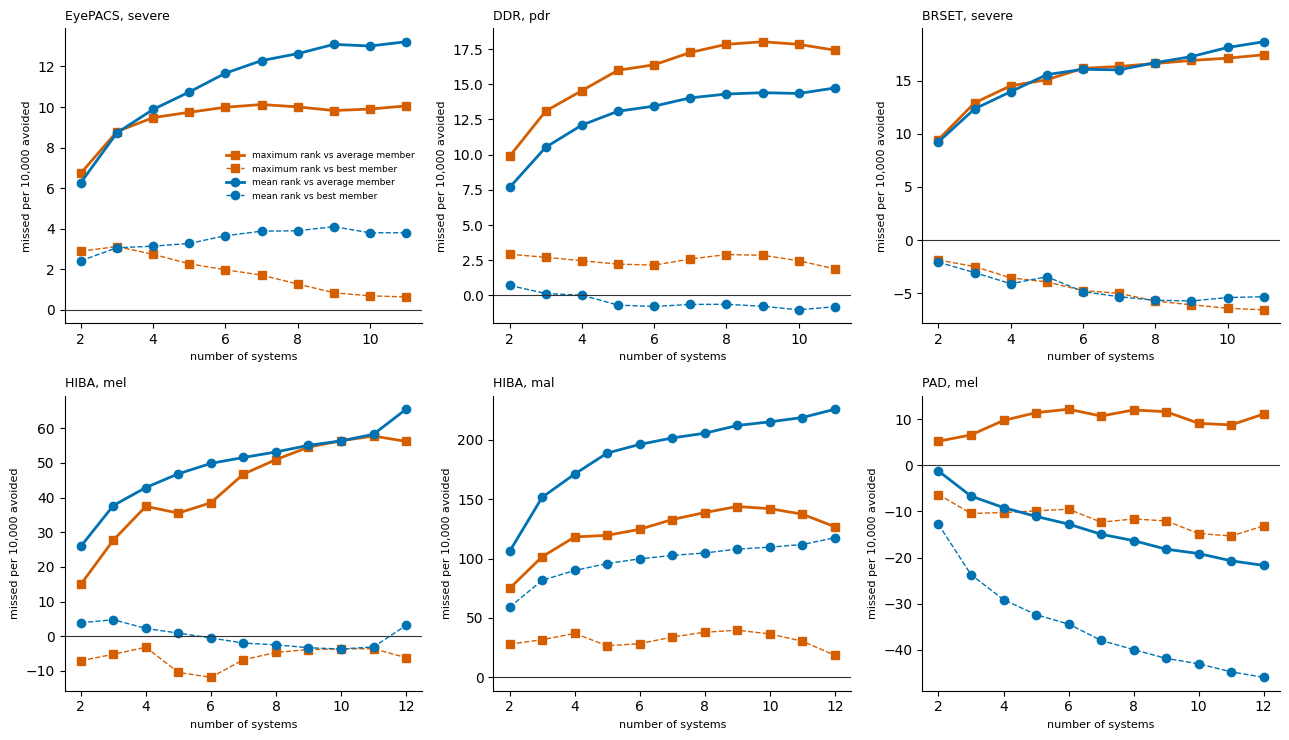

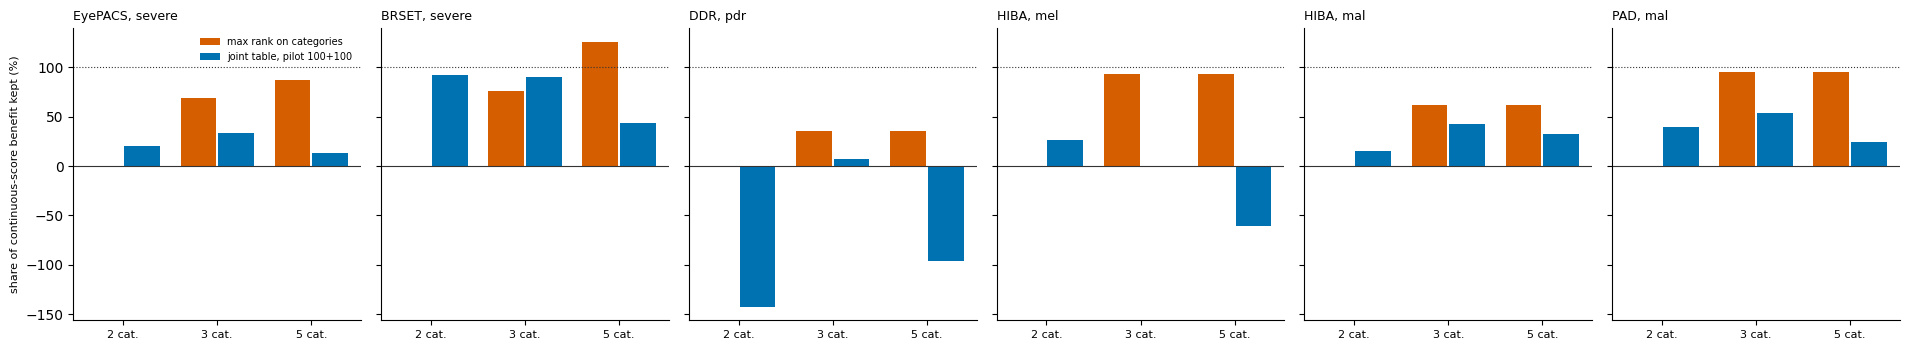

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(13, 7.5))
for x_, key in zip(ax.flat, C_RES):
    o = C_RES[key]; ks = [k for k in o if k > 1]
    for r, col, mk, lab in (("max_rank", "#D55E00", "s", "maximum rank"), ("mean_rank", "#0072B2", "o", "mean rank")):
        x_.plot(ks, [o[k][f"{r}_vs_avg"] for k in ks], color=col, marker=mk, lw=2, label=f"{lab} vs average member")
        x_.plot(ks, [o[k][f"{r}_vs_best"] for k in ks], color=col, marker=mk, lw=1, ls="--", label=f"{lab} vs best member")
    x_.axhline(0, color="#333", lw=0.8); x_.set_title(key.replace("_", ", "), loc="left", fontsize=9); x_.set_xlabel("number of systems", fontsize=8); x_.set_ylabel("missed per 10,000 avoided", fontsize=8)
    [x_.spines[s].set_visible(False) for s in ("top", "right")]
ax.flat[0].legend(fontsize=6.5, frameon=False); fig.tight_layout(); fig.savefig(f"{OUTD}/ensemble_size_c1.png", dpi=200); plt.show()
fig, ax = plt.subplots(1, len(A_RES), figsize=(3.2 * len(A_RES), 3.6), sharey=True)
for x_, key in zip(np.atleast_1d(ax), A_RES):
    o = A_RES[key]; xs = np.arange(len(LEVELS))
    x_.bar(xs - 0.2, [o[f"L{L}"]["share_of_benefit_kept_maxrank"] * 100 for L in LEVELS], 0.38, color="#D55E00", label="max rank on categories")
    tb = [o[f"L{L}"].get(f"pilot_{KPILOT_A[-1]}", {}).get("share_kept_table", [np.nan])[0] * 100 for L in LEVELS]
    x_.bar(xs + 0.2, tb, 0.38, color="#0072B2", label=f"joint table, pilot {KPILOT_A[-1]}+{KPILOT_A[-1]}")
    x_.axhline(100, color="#333", lw=0.8, ls=":"); x_.axhline(0, color="#333", lw=0.8); x_.set_xticks(xs); x_.set_xticklabels([f"{L} cat." for L in LEVELS], fontsize=8)
    x_.set_title(key.replace("_", ", "), loc="left", fontsize=9); [x_.spines[s].set_visible(False) for s in ("top", "right")]
np.atleast_1d(ax)[0].set_ylabel("share of continuous-score benefit kept (%)", fontsize=8); np.atleast_1d(ax)[0].legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(f"{OUTD}/categorical_outputs_c1.png", dpi=200); plt.show()

In [9]:
REC = {"status": "post hoc, exploratory (review cycle 1 discussion); no lock", "written_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
       "A_categorical_outputs": A_RES, "B_fixed_partner": B_RES, "C_ensemble_size": C_RES, "input_sha256": HASHES}
def tolist(x): return {str(k): tolist(v) for k, v in x.items()} if isinstance(x, dict) else ([tolist(v) for v in x] if isinstance(x, (list, tuple)) else (x.tolist() if isinstance(x, np.ndarray) else x))
with open(OUT_JSON, "w") as fh: json.dump(tolist(REC), fh, indent=1, default=float)
drive.flush_and_unmount(); drive.mount("/content/drive"); print("written", OUT_JSON)

Mounted at /content/drive
written /content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2/04_results/revisions_c1/deployment_c1.json
